<a href="https://colab.research.google.com/github/vesakhaa/Statistika_Semester_3/blob/main/Statistika_Jobsheet9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

cabang
Surabaya    0.312
Malang      0.276
Jakarta     0.266
Bandung     0.146
Name: proportion, dtype: float64
cabang
Malang      0.32
Jakarta     0.32
Surabaya    0.24
Bandung     0.12
Name: proportion, dtype: float64
Titik awal: 0, jumlah sampel: 50
cabang
Surabaya    0.38
Jakarta     0.26
Malang      0.24
Bandung     0.12
Name: proportion, dtype: float64
Jumlah sampel: 50
cabang
Surabaya    0.32
Malang      0.28
Jakarta     0.26
Bandung     0.14
Name: proportion, dtype: float64
          Populasi   SRS  Sistematik  Stratified
cabang                                          
Bandung      0.146  0.12        0.12        0.14
Jakarta      0.266  0.32        0.26        0.26
Malang       0.276  0.32        0.24        0.28
Surabaya     0.312  0.24        0.38        0.32


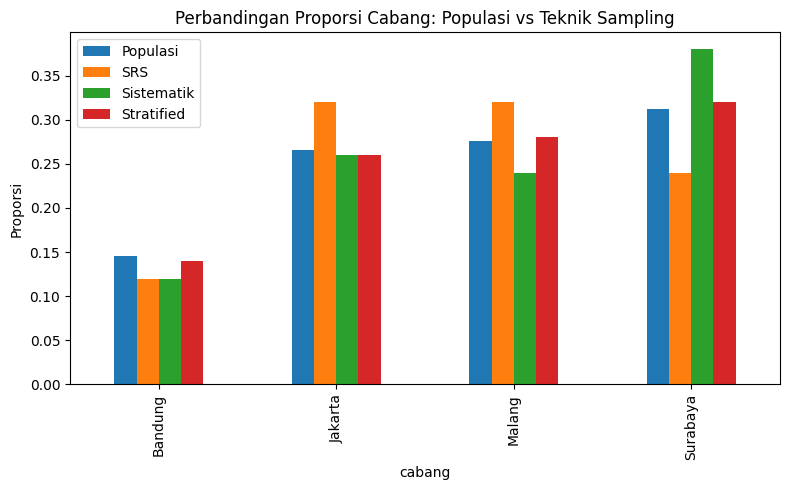

SRS (n=20):
 cabang
Malang      0.45
Jakarta     0.30
Surabaya    0.15
Bandung     0.10
Name: proportion, dtype: float64

SRS (n=100):
 cabang
Malang      0.30
Jakarta     0.29
Surabaya    0.26
Bandung     0.15
Name: proportion, dtype: float64
Jumlah sampel: 101
cabang
Surabaya    0.306931
Malang      0.277228
Jakarta     0.267327
Bandung     0.148515
Name: proportion, dtype: float64
Titik awal: 19, jumlah sampel: 25
cabang
Surabaya    0.40
Jakarta     0.24
Malang      0.24
Bandung     0.12
Name: proportion, dtype: float64


In [13]:
import pandas as pd
import numpy as np

df = pd.read_csv("populasi_pelanggan_elektronikprima.csv")
df.head()

proporsi_populasi = df["cabang"].value_counts(normalize=True)
print(proporsi_populasi)

srs = df.sample(n=50, random_state=42)
proporsi_srs = srs["cabang"].value_counts(normalize=True)
print(proporsi_srs)

titik_awal = np.random.randint(0, 10)
sistematik = df.iloc[titik_awal::10]
proporsi_sistematik = sistematik["cabang"].value_counts(normalize=True)
print(f"Titik awal: {titik_awal}, jumlah sampel: {len(sistematik)}")
print(proporsi_sistematik)

stratified = df.groupby("cabang", group_keys=False)[df.columns] \
                .apply(lambda x: x.sample(frac=0.1, random_state=42))
proporsi_stratified = stratified["cabang"].value_counts(normalize=True)
print(f"Jumlah sampel: {len(stratified)}")
print(proporsi_stratified)

perbandingan = pd.DataFrame({
    "Populasi": proporsi_populasi,
    "SRS": proporsi_srs,
    "Sistematik": proporsi_sistematik,
    "Stratified": proporsi_stratified,
}).round(3)
print(perbandingan)

import matplotlib.pyplot as plt

perbandingan.plot(kind="bar", figsize=(8, 5))
plt.ylabel("Proporsi")
plt.title("Perbandingan Proporsi Cabang: Populasi vs Teknik Sampling")
plt.tight_layout()
plt.show()

# SRS n=20
srs_20 = df.sample(n=20, random_state=42)
prop_srs_20 = srs_20["cabang"].value_counts(normalize=True)
print("SRS (n=20):\n", prop_srs_20)

# SRS n=100
srs_100 = df.sample(n=100, random_state=42)
prop_srs_100 = srs_100["cabang"].value_counts(normalize=True)
print("\nSRS (n=100):\n", prop_srs_100)

strat_20 = df.groupby("cabang", group_keys=False)[df.columns].apply(lambda x: x.sample(frac=0.2, random_state=42))
prop_strat_20 = strat_20["cabang"].value_counts(normalize=True)

print(f"Jumlah sampel: {len(strat_20)}")
print(prop_strat_20)

# Tentukan angka acak baru dari 0 sampai 19
titik_awal = np.random.randint(0, 20)
sistematik_20 = df.iloc[titik_awal::20]
prop_sis_20 = sistematik_20["cabang"].value_counts(normalize=True)

print(f"Titik awal: {titik_awal}, jumlah sampel: {len(sistematik_20)}")
print(prop_sis_20)
